# Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

import matplotlib_inline.backend_inline
matplotlib_inline.backend_inline.set_matplotlib_formats('svg')

# Explore and example

In [2]:
q = np.random.randn(50,50)
k = np.random.randn(50,50)

dp = q @ k.T

In [3]:
# check the means and standard deviations
std_q = np.std(q)
std_k = np.std(k)
std_dp = np.std(dp)

print(f'Standard deviation of  q: {std_q:.4f}')
print(f'Standard deviation of  k: {std_k:.4f}')
print(f'Standard deviation of dp: {std_dp:.4f}')
print(f'Square root of dimension: {np.sqrt(q.shape[1]):.4f}')

Standard deviation of  q: 0.9890
Standard deviation of  k: 1.0110
Standard deviation of dp: 6.9710
Square root of dimension: 7.0711


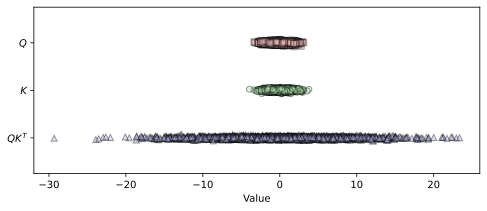

In [4]:
plt.figure(figsize = (8,3))

q_flat = q.flatten()
k_flat = k.flatten()
dp_flat = dp.flatten()
n = len(q_flat)

n = len(q_flat)

plt.plot(
    q_flat,
    np.random.normal(2, 0.02, n),
    "ks",
    markerfacecolor=[0.9, 0.7, 0.7],
    alpha=0.4,
    label="Q",
)

plt.plot(
    k_flat,
    np.random.normal(1, 0.02, n),
    "ko",
    markerfacecolor=[0.7, 0.9, 0.7],
    alpha=0.4,
    label="K",
)

plt.plot(
    dp_flat,
    np.random.normal(0, 0.02, n),
    "k^",
    markerfacecolor=[0.7, 0.7, 0.9],
    alpha=0.4,
    label="QKᵀ",
)

plt.gca().set(
    yticks=[0, 1, 2],
    yticklabels=[r"$QK^T$", r"$K$", r"$Q$"],
    ylim=[-0.75, 2.75],
    xlabel="Value",
)

plt.show()

# Parametric Experiment

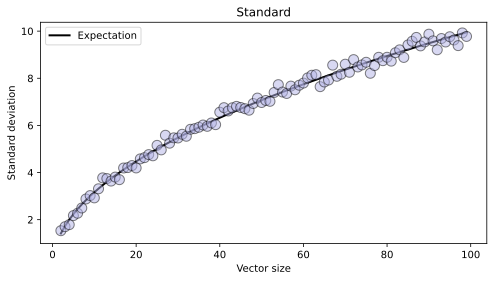

In [5]:
vector_lengths = np.arange(2, 100)

dp_stds = np.zeros(len(vector_lengths))

for l in range(len(vector_lengths)):

  # create two matrices
  q = np.random.randn(50, vector_lengths[l])
  k = np.random.randn(50, vector_lengths[l])

  dps = q@k.T

  dp_stds[l] = np.std(dps)

plt.figure(figsize= (8,4))
plt.plot(vector_lengths, np.sqrt(vector_lengths), 'k', linewidth = 2, label = 'Expectation')
plt.plot(vector_lengths, dp_stds, 'ko', markersize = 10, markerfacecolor = [.7,.7,.9], alpha = .5)

plt.legend()
plt.gca().set(xlabel = 'Vector size', ylabel = 'Standard deviation', title = 'Standard')
plt.show()

If insread we will add std of q and k separately it stays constant.

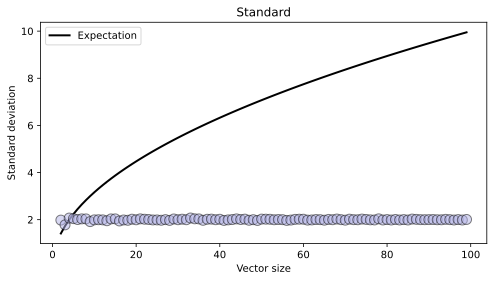

In [6]:
vector_lengths = np.arange(2, 100)

dp_stds = np.zeros(len(vector_lengths))

for l in range(len(vector_lengths)):

  # create two matrices
  q = np.random.randn(50, vector_lengths[l])
  k = np.random.randn(50, vector_lengths[l])

  dps = q@k.T

  dp_stds[l] = np.std(q) + np.std(k)

plt.figure(figsize= (8,4))
plt.plot(vector_lengths, np.sqrt(vector_lengths), 'k', linewidth = 2, label = 'Expectation')
plt.plot(vector_lengths, dp_stds, 'ko', markersize = 10, markerfacecolor = [.7,.7,.9], alpha = .5)

plt.legend()
plt.gca().set(xlabel = 'Vector size', ylabel = 'Standard deviation', title = 'Standard')
plt.show()

# Implications for Softmax

* 50X50 Q and K to create $QK^T$
* Calculate softmax and -nll
* Repeat after scaling $QK^T$ by $\sqrt{N}$

Here, we try to demonstrate importance of $\sqrt(d_k)$ in scaled dot-product attention:

$$Attention(Q,K,V) = softmax\Big( \frac{QK^T}{\sqrt{d_k}} \Big)V$$

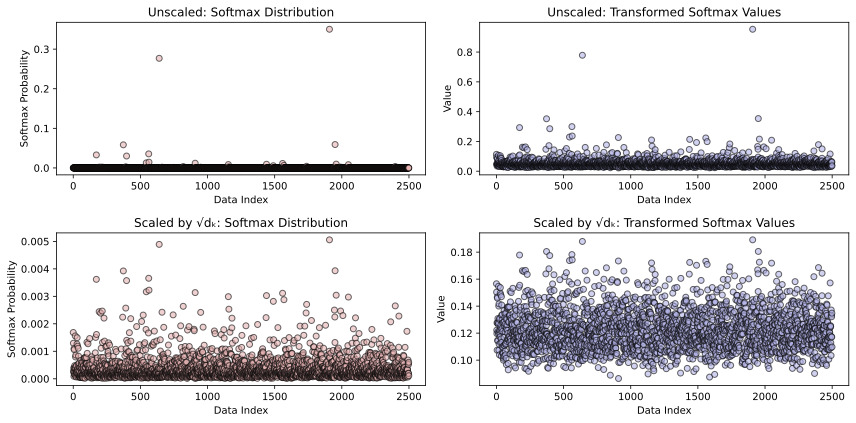

In [13]:
# create two vectors
q = np.random.randn(50, 50)
k = np.random.randn(50, 50)

# their dot product
dps = q @ k.T

_, axs = plt.subplots(2, 2, figsize=(12, 6))

for i in range(2):

    scaling_label = "Unscaled"

    if i == 1:
        dps /= np.sqrt(q.shape[1])
        scaling_label = "Scaled by √dₖ"

    dps_flat = dps.flatten()
    softmax = np.exp(dps_flat) / np.sum(np.exp(dps_flat))
    nll = -1 / np.log(softmax)

    axs[i, 0].plot(
        softmax,
        "ko",
        markerfacecolor=[.9, .7, .7],
        alpha=.6
    )
    axs[i, 0].set(
        xlabel="Data Index",
        ylabel="Softmax Probability",
        title=f"{scaling_label}: Softmax Distribution"
    )

    axs[i, 1].plot(
        nll,
        "ko",
        markerfacecolor=[.7, .7, .9],
        alpha=.6
    )
    axs[i, 1].set(
        xlabel="Data Index",
        ylabel="Value",
        title=f"{scaling_label}: Transformed Softmax Values"
    )

plt.tight_layout()
plt.show()

The conclusion is that we want to have model (0,0) behaviour BUT the very important aspect is that we want it only if the model is very well trained. If the model returns such outcomes, not being trained we have "overconfident" model that cannot explore by selecting other tokens. While training we want the values to be relatively small but not too small to keep model learning. However, the ultimate goal is to make model very confident about its predictions.

# Check GPT2's layer_norm parameters

In [8]:
from transformers import AutoModelForCausalLM, GPT2Tokenizer
gpt2 = AutoModelForCausalLM.from_pretrained('gpt2')

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

In [9]:
for name, mat in gpt2.named_parameters():
  print(f'{name:<40}', mat.shape)

transformer.wte.weight                   torch.Size([50257, 768])
transformer.wpe.weight                   torch.Size([1024, 768])
transformer.h.0.ln_1.weight              torch.Size([768])
transformer.h.0.ln_1.bias                torch.Size([768])
transformer.h.0.attn.c_attn.weight       torch.Size([768, 2304])
transformer.h.0.attn.c_attn.bias         torch.Size([2304])
transformer.h.0.attn.c_proj.weight       torch.Size([768, 768])
transformer.h.0.attn.c_proj.bias         torch.Size([768])
transformer.h.0.ln_2.weight              torch.Size([768])
transformer.h.0.ln_2.bias                torch.Size([768])
transformer.h.0.mlp.c_fc.weight          torch.Size([768, 3072])
transformer.h.0.mlp.c_fc.bias            torch.Size([3072])
transformer.h.0.mlp.c_proj.weight        torch.Size([3072, 768])
transformer.h.0.mlp.c_proj.bias          torch.Size([768])
transformer.h.1.ln_1.weight              torch.Size([768])
transformer.h.1.ln_1.bias                torch.Size([768])
transformer.h.1.at

In [10]:
# gather all layernorm parameters into vectors
all_ln_weights = np.array([])
all_ln_biases  = np.array([])

for name, mat in gpt2.named_parameters():
  if 'ln' in name and 'weight' in name:
    all_ln_weights = np.append(all_ln_weights, mat.data) # append automatically does flatten
  elif 'ln' in name and 'bias' in name:
    all_ln_biases  = np.append(all_ln_biases,  mat.data)

/tmp/ipykernel_445/3758794916.py:6: RuntimeWarning: divide by zero encountered in log
  axs[0].plot(x_w[:-1], np.log(y_w), 'ks-', markerfacecolor = [.9,.7,.7])
/tmp/ipykernel_445/3758794916.py:9: RuntimeWarning: divide by zero encountered in log
  axs[1].plot(x_b[:-1], np.log(y_b), 'ko-', markerfacecolor = [.7,.7,.9])


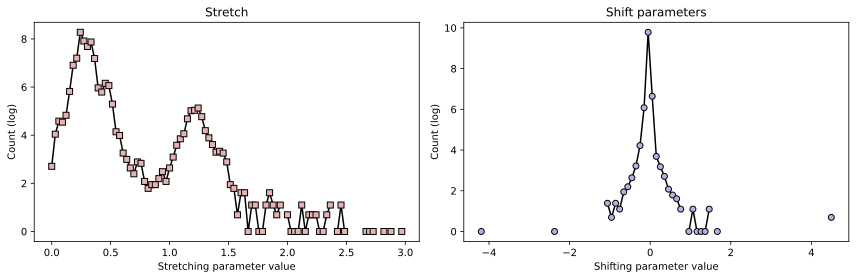

In [11]:
y_w, x_w = np.histogram(all_ln_weights, bins = np.linspace(0,3,100))
y_b, x_b = np.histogram(all_ln_biases,  bins = np.linspace(-5,5,100))

# and plot
_, axs = plt.subplots(1,2,figsize=(12,4))
axs[0].plot(x_w[:-1], np.log(y_w), 'ks-', markerfacecolor = [.9,.7,.7])
axs[0].set(xlabel = 'Stretching parameter value', ylabel = 'Count (log)', title = 'Stretch')

axs[1].plot(x_b[:-1], np.log(y_b), 'ko-', markerfacecolor = [.7,.7,.9])
axs[1].set(xlabel = 'Shifting parameter value', ylabel = 'Count (log)', title = 'Shift parameters')

plt.tight_layout()
plt.show()

* Each amtrix multiplication (dot products) increases the variance and numerical range of numbers
* This can have a negative impact on softmax probabilities by flattening the distribution
* Repeated normalization is very important for the stability of deep learning models including LLMs  